# Trabajo Práctico Nro. 2 - Transformada de Fourier y Procesamientos Básicos de Señales

Grupo 10, 2Q2026

Integrantes:

- Ana Negre
- Juan José Medina

In [217]:
pip install numpy matplotlib wget scipy control schemdraw --quiet


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Aplicación de la Transformada de Fourier
A continuación se computa la transformada de fourier en su forma computacional, con el fin de analizar tanto las señales reales obtenidas del trabajo práctico anterior como algunas de las señales base.

In [218]:
import numpy as np
import matplotlib.pyplot as plt

#### Obtención de archivos
En primer lugar, se obtienen los archivos correspondientes al ECG y PCG utilizados en el anterior trabajo, de la misma forma que fue detallado en el mismo.

[Fuente: Pshysio.net](https://physionet.org/content/ephnogram/1.0.0/MAT/#files-panel)

In [219]:
import os

URL = "https://physionet.org/files/ephnogram/1.0.0/MAT/"
FILE = "ECGPCG0010.mat"  # from 00 to 69

target_dir = "./data/"
os.makedirs(target_dir, exist_ok=True)

filepath = os.path.join(target_dir, FILE)

if not os.path.exists(filepath):
  !wget --no-check-certificate -P {target_dir} {URL}{FILE}

In [220]:
from scipy.io import loadmat

data = loadmat(os.path.join(target_dir, FILE))
print(data.keys())
ecg = data['ECG'].flatten()
pcg = data['PCG'].flatten()
fs = int(data['fs'].flatten()[0])

print(f"ECG length: {len(ecg)}, sampling rate: {fs} Hz")
print(f"ECG duration: {len(ecg)/fs:.1f} seconds")
print(f"ECG samples: {len(ecg):.1f}")

print(f"PCG length: {len(pcg)}, sampling rate: {fs} Hz")
print(f"PCG duration: {len(pcg)/fs:.1f} seconds")
print(f"PCG samples: {len(pcg):.1f}")



dict_keys(['__header__', '__version__', '__globals__', 'ECG', 'PCG', 'fs'])
ECG length: 14400000, sampling rate: 8000 Hz
ECG duration: 1800.0 seconds
ECG samples: 14400000.0
PCG length: 14400000, sampling rate: 8000 Hz
PCG duration: 1800.0 seconds
PCG samples: 14400000.0


Se observa que el sampling rate, o frecuencia de muestreo de las señales es de $8000 Hz$. Luego por teorema de muestreo, sabemos que:
$$x[n]=x_c(nT)=x_c(\frac{n}{f_s})$$

Si bien se trata de señales discretas, la resolución permite tomar las mismas como una señales continuas, y graficarlas como tal:

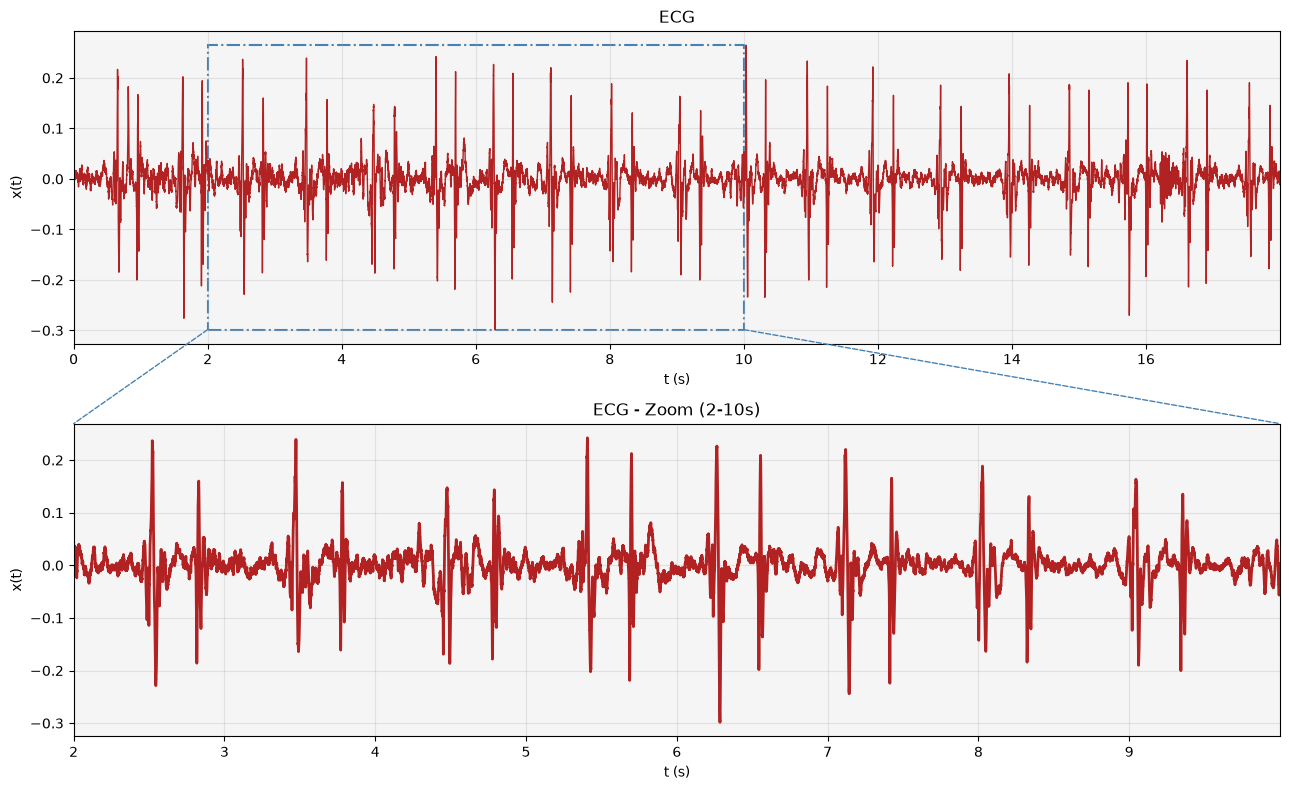

In [221]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, ConnectionPatch

t = np.arange(len(ecg)) / fs
window = slice(0, int(fs * 18))
window_zoom = slice(int(fs * 2), int(fs * 10))  # subset de 8s

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), facecolor='white')

# grafico completo
ax1.set_facecolor('whitesmoke')
ax1.plot(t[window], pcg[window], linewidth=1, color="firebrick")
ax1.set_xlim(t[window].min(), t[window].max())
ax1.grid(True, alpha=0.3)
ax1.set_title('ECG')
ax1.set_xlabel('t (s)')
ax1.set_ylabel("x(t)")

# rectángulo para ver el zoom in
t_zoom_start = t[window_zoom].min()
t_zoom_end = t[window_zoom].max()
y_min, y_max = pcg[window].min(), pcg[window].max()
rect = Rectangle(
    (t_zoom_start, y_min), t_zoom_end - t_zoom_start, y_max - y_min,
    linewidth=1.5, edgecolor='steelblue', facecolor='none', linestyle='-.'
)
ax1.add_patch(rect)

# grafico zoom
ax2.set_facecolor('whitesmoke')
ax2.plot(t[window_zoom], pcg[window_zoom], linewidth=2, color="firebrick")
ax2.set_xlim(t[window_zoom].min(), t[window_zoom].max())
ax2.grid(True, alpha=0.3)
ax2.set_title('ECG - Zoom (2-10s)')
ax2.set_xlabel('t (s)')
ax2.set_ylabel("x(t)")
y_zoom_min, y_zoom_max = pcg[window_zoom].min(), pcg[window_zoom].max()

# conectores
con1 = ConnectionPatch(
    xyA=(t_zoom_start, y_min), coordsA=ax1.transData,
    xyB=(0, 1), coordsB=ax2.transAxes,
    color='steelblue', linestyle='--', linewidth=1
)

con2 = ConnectionPatch(
    xyA=(t_zoom_end, y_min), coordsA=ax1.transData,
    xyB=(1, 1), coordsB=ax2.transAxes,
    color='steelblue', linestyle='--', linewidth=1
)
fig.add_artist(con1)
fig.add_artist(con2)

plt.tight_layout()
# plt.show()

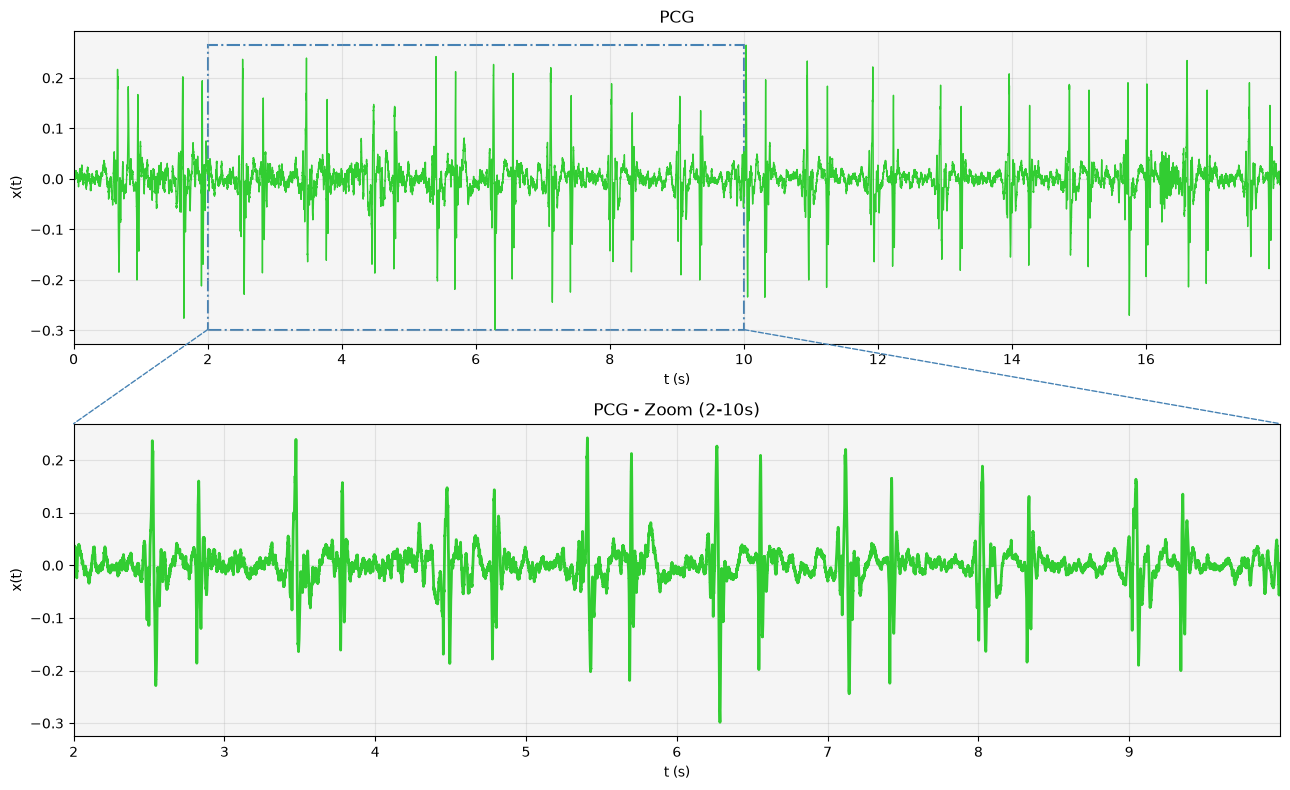

In [222]:
# @title
from matplotlib.patches import Rectangle, ConnectionPatch

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), facecolor='white')

# grafico completo
ax1.set_facecolor('whitesmoke')
ax1.plot(t[window], pcg[window], linewidth=1, color="limegreen")
ax1.set_xlim(t[window].min(), t[window].max())
ax1.grid(True, alpha=0.3)
ax1.set_title('PCG')
ax1.set_xlabel('t (s)')
ax1.set_ylabel("x(t)")

# rectángulo para ver el zoom in
t_zoom_start = t[window_zoom].min()
t_zoom_end = t[window_zoom].max()
y_min, y_max = pcg[window].min(), pcg[window].max()
rect = Rectangle(
    (t_zoom_start, y_min), t_zoom_end - t_zoom_start, y_max - y_min,
    linewidth=1.5, edgecolor='steelblue', facecolor='none', linestyle='-.'
)
ax1.add_patch(rect)

# grafico zoom
ax2.set_facecolor('whitesmoke')
ax2.plot(t[window_zoom], pcg[window_zoom], linewidth=2, color="limegreen")
ax2.set_xlim(t[window_zoom].min(), t[window_zoom].max())
ax2.grid(True, alpha=0.3)
ax2.set_title('PCG - Zoom (2-10s)')
ax2.set_xlabel('t (s)')
ax2.set_ylabel("x(t)")
y_zoom_min, y_zoom_max = pcg[window_zoom].min(), pcg[window_zoom].max()

# conectores
con1 = ConnectionPatch(
    xyA=(t_zoom_start, y_min), coordsA=ax1.transData,
    xyB=(0, 1), coordsB=ax2.transAxes,
    color='steelblue', linestyle='--', linewidth=1
)

con2 = ConnectionPatch(
    xyA=(t_zoom_end, y_min), coordsA=ax1.transData,
    xyB=(1, 1), coordsB=ax2.transAxes,
    color='steelblue', linestyle='--', linewidth=1
)
fig.add_artist(con1)
fig.add_artist(con2)

plt.tight_layout()
# plt.show()

Luego se puede muestrear las señales de PCG y ECG, observando que dado que el período de muestreo de las señales es: $\frac{1}{fs}=0.000125s$, el período elegido de muestreo debe ser igual o superior al mismo.
Se elige $T=0.5$.

A continuación se grafican las señales discretas obtenidas, recortando lo obtenido a $2-4s$ para simplificar la visualización. No se explicita el método de muestreo ideal via conversor A/D puesto a que ya fue detallado en el trabajo anterior.

In [223]:
def hacer_x_c_desde_array(t_data, x_data):
    def x_c(t_eval):
        return np.interp(t_eval, t_data, x_data)
    return x_c

def plot_señal_muestreada(x_c, t, T, titulo_senal=r'$x_c(t)$', figsize=(8, 4),color='limegreen'):
    step = t[1] - t[0]
    N = int(round(T / step))

    t_n = t[::N]
    n = np.arange(len(t_n))
    xc_cont = x_c(t)
    xc_en_tn = xc_cont[::N]

    fig, ax = plt.subplots(1, 1, figsize=figsize)

    markerline, stemlines, baseline = ax.stem(n, xc_en_tn, basefmt=" ")
    plt.setp(markerline, color=color)
    plt.setp(stemlines, color=color)
    ax.set_title(titulo_senal)
    ax.set_xlabel('n')
    ax.grid(True)

    plt.tight_layout()
    return fig, ax, (n, t_n, xc_en_tn)

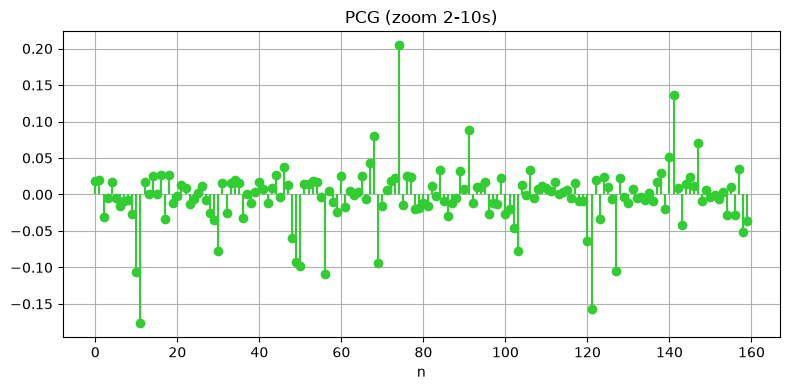

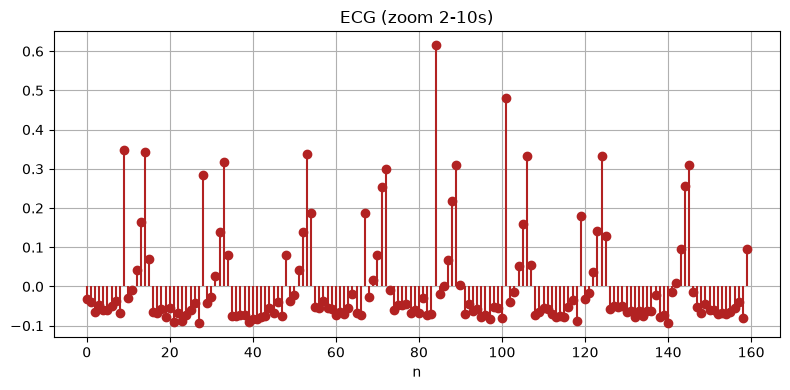

In [224]:
fs = 8000
t = np.arange(len(pcg)) / fs

window = slice(int(fs*2), int(fs*10))
t_win = t[window]
pcg_win = pcg[window]

x_c_pcg_win = hacer_x_c_desde_array(t_win, pcg_win)
fig, axs, (n, t_n, xn) = plot_señal_muestreada(x_c_pcg_win, t_win, T=0.05, titulo_senal='PCG (zoom 2-10s)',figsize=(8,4),color='limegreen')

ecg_win = ecg[window]
x_c_ecg_win = hacer_x_c_desde_array(t_win, ecg_win)
fig, axs, (n, t_n, xn) = plot_señal_muestreada(x_c_ecg_win, t_win, T=0.05, titulo_senal='ECG (zoom 2-10s)',figsize=(8,4),color='firebrick')


#### Transformada de Fourier

A partir de las señales discretas obtenidas, puede aplicarse la transformada de Fourier de tiempo discreto para obtener la información de la señal en términos de frecuencia.
Para obtener la DTFT de una señal, debe hacerse:
$$
  \hat{X}=\mathcal{F}_d\{x[n]\}(f)=\sum_{n=-\infty}^{+\infty}x[n]e^{-i2\pi f_d n}
$$
Esta expresión presenta distintos problemas de implementación, dado que _no_ es computable. En primer lugar, la sumatoria exige una cantidad infinita de muestras, con lo cual no es compatible con señales reales (sin descripción analítica). Por el otro lado, la DTFT trabaja con frecuencia continua, lo cual implica un problema de implementación, ya que no pueden almacenarse todas las frecuencias.

Luego puede proponerse la DFT como solución a estos problemas. La idea es "muestrear" la DTFT a partir de una cantidad N de muestras:
$$
X[k]=\sum_{n=0}^{N-1}x[n]e^{-i2\pi f_k n}\qquad f_k=\frac{k}{N}, k\in \{0,...,N-1\}
$$
De esta manera, se pasa a trabajar con secuencias finitas y espectro en variable discreta, aproximando así la transformada de Fourier de tiempo discreto.
En particular, puede utilizarse el algoritmo FFT para calcular DFT.

Luego puede aplicarse este algoritmo para computar la transformada de las señalkes de PCG y ECG. Cabe aclarar que para esto es necesario que las señales sean de _largo finito_, lo cual estas señales cumplen dado que son señales reales no definidas fuera del tiempo observado.
Para acortar el tiempo de ejecución, se toma la ventana utilizada previamente de $8s$ para computar la DFT de las señales de PCG y ECG.

In [225]:
## referencia de: https://agustinsolano.github.io/SyS_scriptsbook/md_scripts/Computo_TFourier_FFT_senial_real.html

import numpy as np
import matplotlib.pyplot as plt

def dtft_muestreada(x, fs, nfft=None):
    x = np.asarray(x)
    if nfft is None:
        nfft = len(x) # default es N, cantidad de muestras

    X = np.fft.fftshift(np.fft.fft(x, n=nfft))
    k = np.arange(-(nfft // 2), nfft - nfft // 2)
    f = k * fs / nfft
    return f, X

def plot_dtft(x, fs, nfft=None, titulo='PCG', umbral_fase=1e-3, fmax=500, color='C0'):
    f, X = dtft_muestreada(x, fs, nfft)
    sel = np.abs(f) <= fmax
    f_p, X_p = f[sel], X[sel]

    mag = np.abs(X_p)
    fase = np.angle(X_p)
    fase[mag < umbral_fase * mag.max()] = 0 # en teoría fuera del rango de info del módulo la fase debiiera ser ruido

    fig, axs = plt.subplots(2, 1, figsize=(12, 8))

    ml, sl, _ = axs[0].stem(f_p, mag, basefmt=" ")
    plt.setp(ml, color=color, markersize=3); plt.setp(sl, color=color, linewidth=0.8)
    axs[0].set_title(rf'{titulo} - $|X(f_k)|$')
    axs[0].set_ylabel('Magnitud [u.a.]'); axs[0].grid(True)
    axs[0].set_xlabel('Frecuencia [Hz]')

    ml, sl, _ = axs[1].stem(f_p, fase, basefmt=" ")
    plt.setp(ml, color=color, markersize=3); plt.setp(sl, color=color, linewidth=0.8)
    axs[1].set_title(rf'{titulo} - $\angle X(f_k)$')
    axs[1].set_ylabel('Fase [rad]')
    axs[1].set_xlabel('Frecuencia [Hz]')
    axs[1].grid(True)

    axs[0].set_xlim(-fmax, fmax)
    plt.tight_layout()
    return fig, axs, (f, X)      # devuelve el espectro completo, no solo el recortado

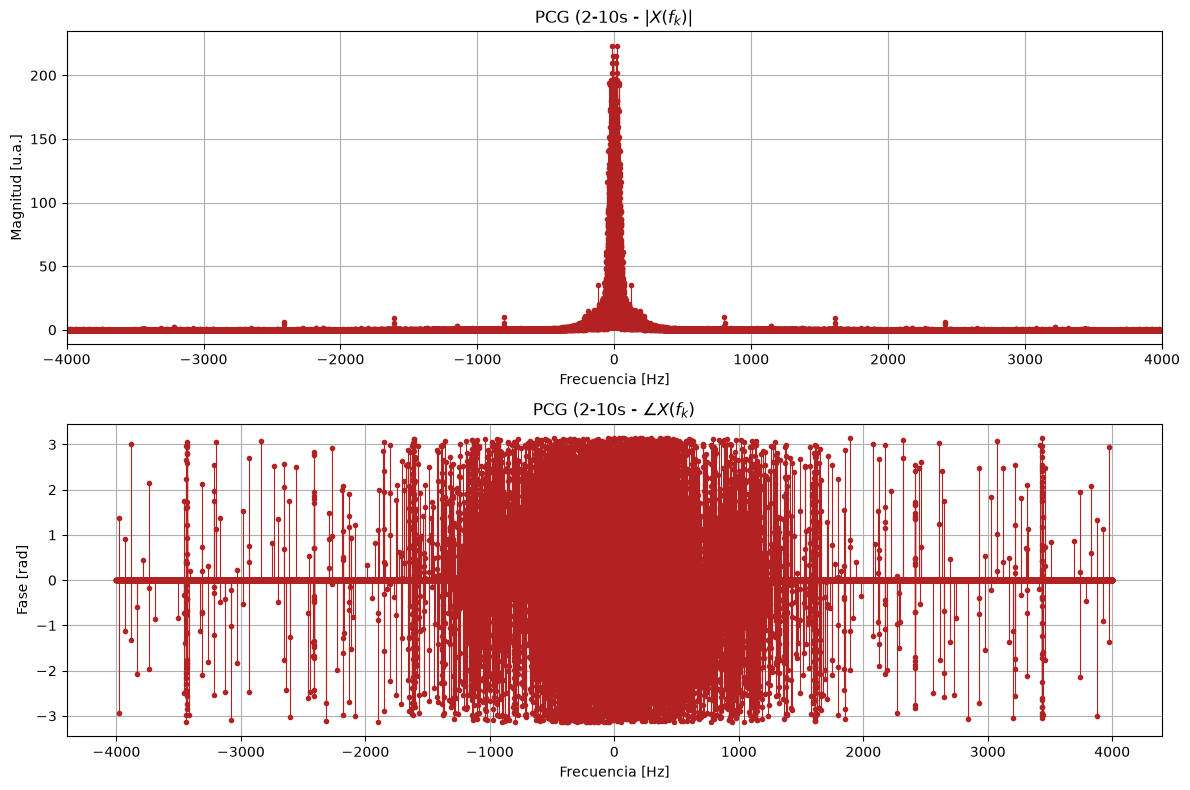

In [226]:
fig, axs, (f, X) = plot_dtft(pcg_win, fs, titulo='PCG (2-10s', fmax=fs/2,color='firebrick')

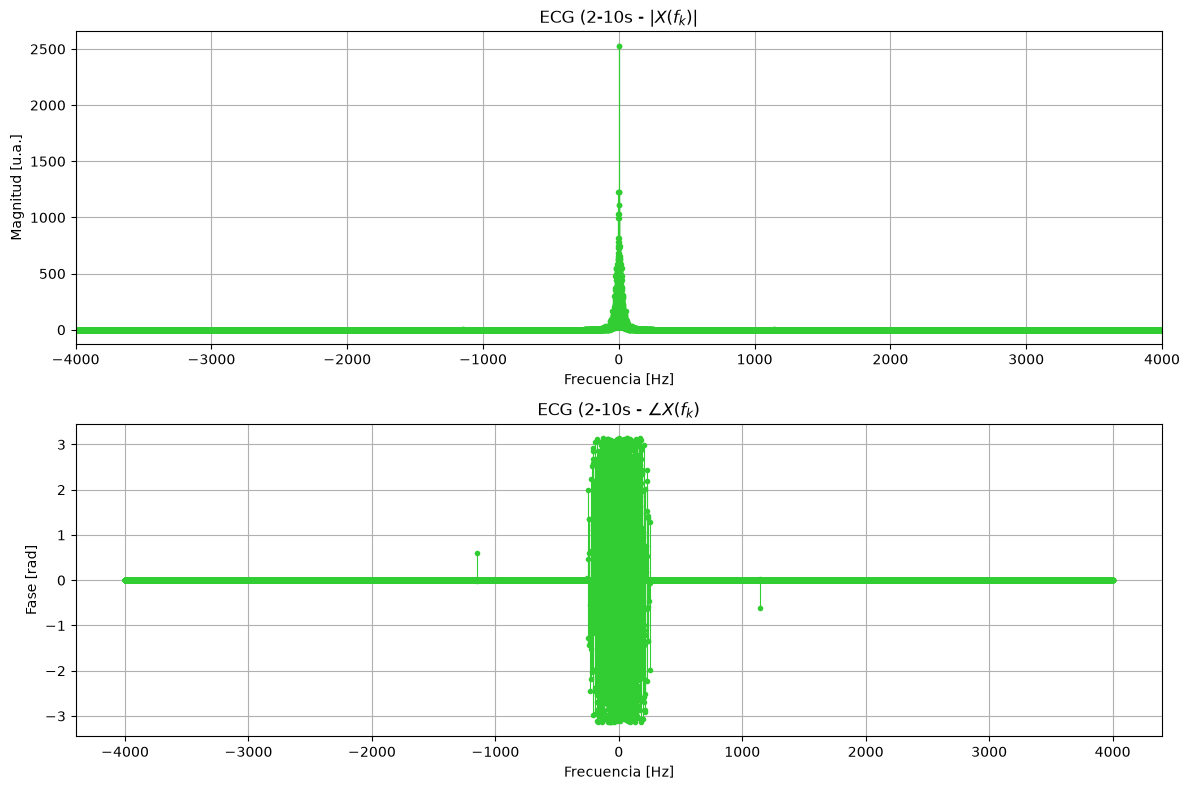

In [227]:
fig, axs, (f, X) = plot_dtft(ecg_win, fs, titulo='ECG (2-10s', fmax=fs/2,color='limegreen')

#### Análisis de ECG y PCG

El ECG (o electrocardiograma) es un estudio que mide la actividad eléctrica del corazón. Dentro del mismo pueden identificarse distintas ondas, correspondientes a los eventos que se repiten en cada latido a nivel eléctrico. En particular:

- **P**: resultado de la activación eléctrica de las aurículas (cavidades superiores del corazón). Es una onda pequeña y redondeada, de duración $\leq 120 \mathrm{ms}$ y amplitud $\leq 0.25\mathrm{mV}$. Su contenido en frecuencia se concentra entre 5 y 30 Hz como máximo.
- **Q, R, S**: producto de la activación de los ventrículos (cavidades infriores). La R es el pico más alto y angosto de la señal. Dura unos 70-110 ms y concentra su energía entre 8 y 50 Hz, centrado en 10 Hz.
- **T**: repolarización de los ventrículos. Es una onda ancha y lenta, con contenido principalmente entre 0 y 10 Hz.
- **RR**: no es una onda sino el intervalo entre dos picos R consecutivos, es decir, la duración de un latido. A partir de él se obtienen la frecuencia cardíaca y la variabilidad del ritmo. Corresponde a una frecuencia de aproximadamente 1 Hz (dependiendo el ritmo cardíaco del paciente).

El PCG (fonocardiograma), por el otro lado, registra los sonidos cardíacos mediante un micrófono colocado en la pared torácica del paciente. Pueden identificarse distintos eventos a partir de los sonidos detectados:

- **S1**: primer ruido cardíaco, producido por el cierre de las válvulas mitral y tricúspide al inicio de la sístole. Ocurre inmediatamente después del pico R del ECG. Su contenido en frecuencia se extiende de unos 10 a 150 Hz, con máxima energía alrededor de 25-45 Hz.
- **S2**: segundo ruido cardíaco, producido por el cierre de las válvulas aórtica y pulmonar al final de la sístole, cerca del final de la onda T. Es algo más agudo que S1: abarca de unos 10 a 200 Hz, con máxima energía alrededor de 55-75 Hz.
- **S3/S4**: sonidos débiles de la diástole, de muy baja frecuencia (aproximadamente 15-70 Hz).
- **Soplos**: producidos por flujo turbulento, de mayor frecuencia y carácter ruidoso, entre unos 25 y 400 Hz, pudiendo extenderse hasta unos 600 Hz con menor energía. Representan anomalías cardíacas.

Los intervalos entre S1 y S2 representan la _sístole_ y entre S2 y el siguiente S1 la _diástole_. La presencia de componentes de alta frecuencia en ellos es un indicio de soplos o _clics_.

A partir de la DFT de las señales, podemos observar que el contenido de las mismas se concentra alrededor de las bajas frecuencias. Esto puede verse más claramente al graficar alrededor de este rango. Esto es consistente con el origen de las señales: la información del ECG se encuentra dentro de la franja de $150Hz$ como máximo, y el PCG contiene información hasta $400Hz$ si se detectan anomalías como soplos.


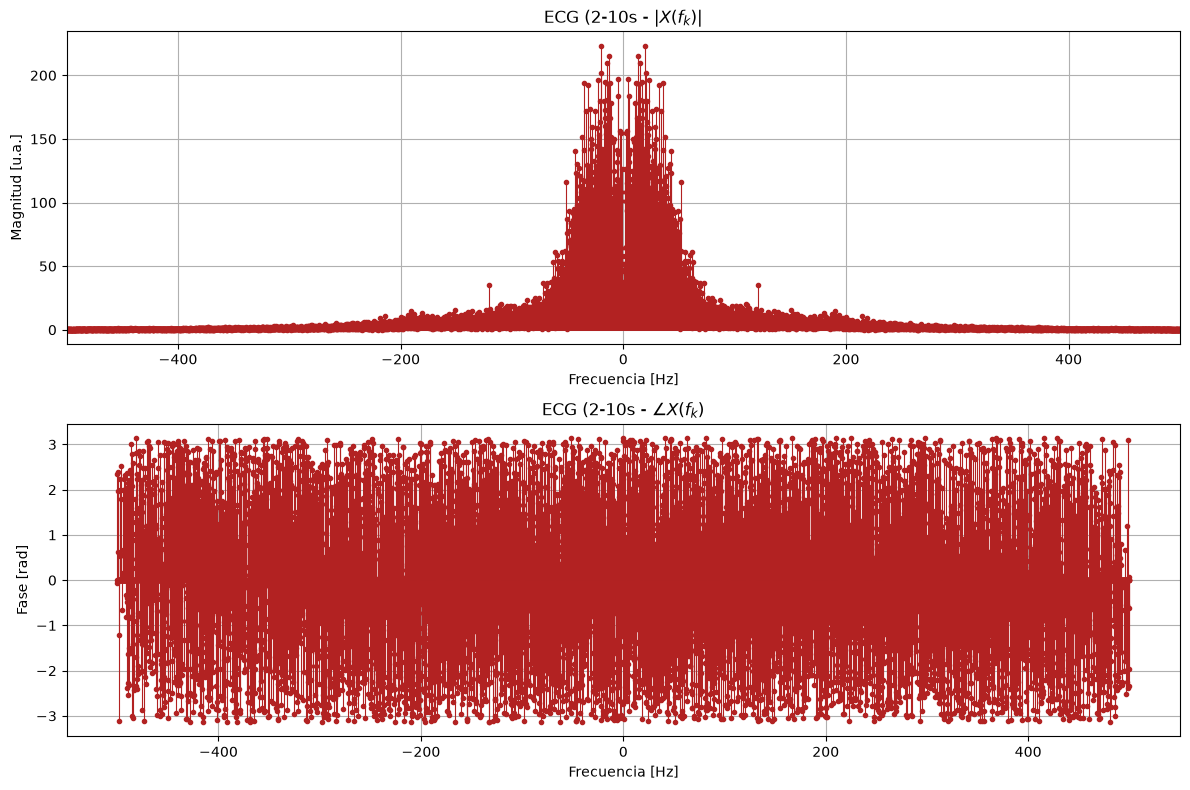

In [228]:
fig, axs, (f, X) = plot_dtft(pcg_win, fs, titulo='ECG (2-10s', fmax=500,color='firebrick')

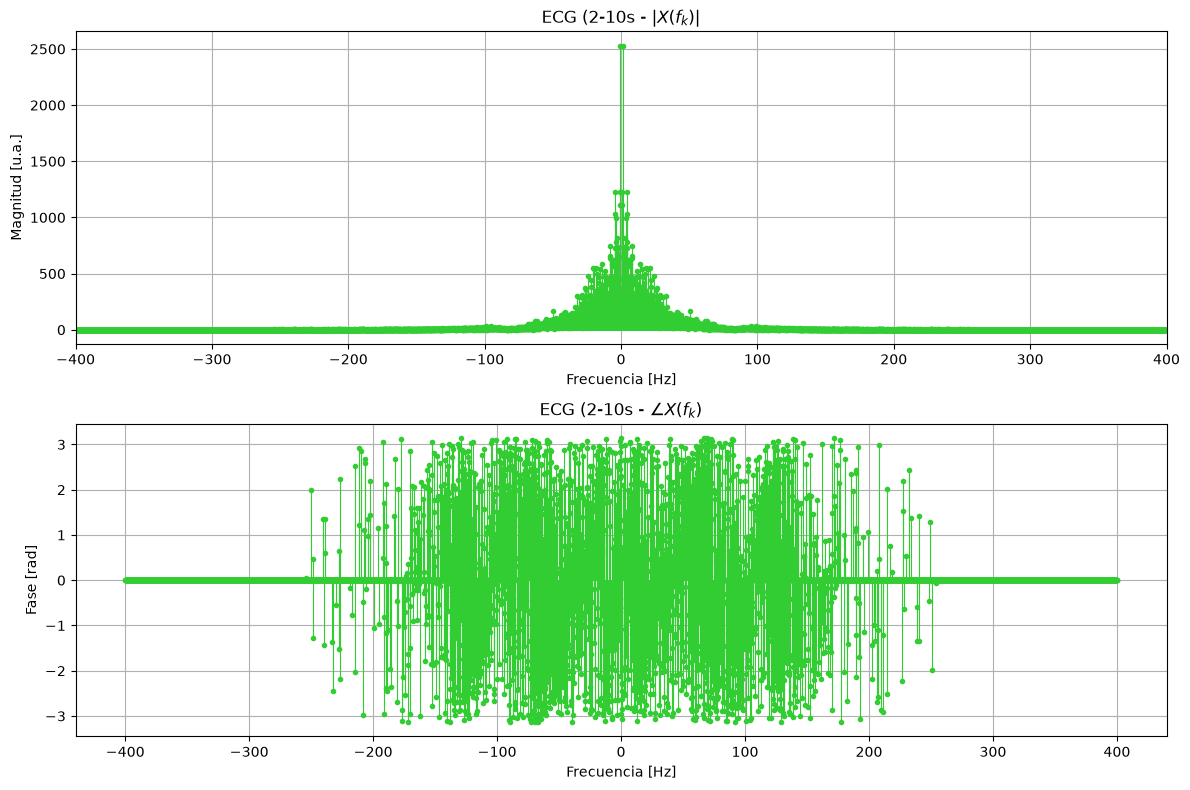

In [235]:
fig, axs, (f, X) = plot_dtft(ecg_win, fs, titulo='ECG (2-10s)', fmax=400,color='limegreen')

Luego para analizar la información de las señales, pueden emplearse filtros para rechazar el ruido introducido durante las mediciones (pasa-bajos con frecuencia de corte en $\sim 400Hz$ para PCG, y en $\sim 150Hz$ para ECG), y luego procesarlas (con otros filtros, o incluso utilizando una red neuronal a modo de clasificador), para identificar las ondas que componen estas señales, aislarlas, y detectar anomalías.

En particular, para detectar la onda QRS puede utilizarse un filtro pasa-banda que rechaza frecuencias fuera del rango $5-15Hz$, dado que es en esta banda donde se concentra gran parte de su energía (Pan y Tompkins, 1985 ([fuente](https://www.robots.ox.ac.uk/~gari/teaching/cdt/A3/readings/ECG/Pan+Tompkins.pdf))).

Sin embargo, como varias de las ondas comparten parte de sus bandas de frecuencia, no siempre es posible aislarlas únicamente utilizando filtros. En el ECG, la onda P ($\sim 5\text{-}30\,\mathrm{Hz}$) y el complejo QRS ($\sim 8\text{-}50\,\mathrm{Hz}$) se superponen en frecuencia, y la onda T ($\sim 0\text{-}10\,\mathrm{Hz}$) se superpone con la P. En el PCG, S1 y S2 ocupan bandas muy parecidas, y los soplos, de mayor frecuencia, aparecen en los intervalos entre ambos sonidos, de modo que la frecuencia por sí sola no permite distinguir un sonido de otro.
Por este motivo, el filtrado se debe combinar con información temporal: pueden detectarse los picos R y, tomando ventanas de tiempo respecto de ellos, aislar cada onda del ECG y promediar los latidos para reducir el ruido. De la misma forma, en el PCG se pueden ubicar S1 y S2 a partir del pico R y analizar por separado la sístole y la diástole.

## Implementación de Procesamientos Básicos

A continuación se implementan distintos procesamientos básicos de señales. Cada procesamiento se modela como un sistema, observando el resultado al poner en la entrada las señales de ECG y PCG, analizando la salida en el dominio temporal y frecuencial.

#### Submuestreo y sobremuestreo


#### Inversor

#### Sumador

#### Promediador

#### Inversor

#### Modelado de sistema a partir de circuito RLC


## Referencias
- https://advancedmedicalcertification.com/pqrst-wave-explained-for-beginners
- https://agustinsolano.github.io/SyS_scriptsbook/md_scripts/Computo_TFourier_FFT_senial_real.html
- https://pmc.ncbi.nlm.nih.gov/articles/PMC12953169/
- https://www.robots.ox.ac.uk/~gari/teaching/cdt/A3/readings/ECG/Pan+Tompkins.pdf